#  **Prática: Análise de Regressão Logística**

In [1]:
# importa as bibliotecas
import pandas as pd
import numpy as np


Inicialmente, vamos importar o conjunto de dados ECG, com os dados do estudo sobre Doença Arterial Coronariana (DAC).

In [2]:
# importa o data set
from google.colab import files
uploaded = files.upload()

# abro o dataset e nomeio cada coluna com meu vetor columns
data = pd.read_csv('ECG.csv')

# visualiza a tabela, o método head() mostra as 5 primeiras linhas da tabela
# note que a coluna 'dac' é a variável dependente ou resposta (1 para quem tem DAC e 0 para quem não tem DAC).
# o restante das colunas são as variáveis explicativas ou independentes ou preditoras (features, atributos), e cada linha é um indivíduo (instância ou exemplo).
data.head()

Saving ECG.csv to ECG.csv


,dac,sexo,ecg,idade
0,0,0,0,28
1,0,0,0,34
2,0,0,0,38
3,1,0,0,41
4,0,0,0,44


In [ ]:
# mostra o número de linhas (unidades amostrais) e colunas (variáveis)
data.shape

(78, 4)

Inicialmmente, vamos ajustar um modelo de regressão logística apenas com uma variável explicativa: idade.

In [ ]:
import statsmodels.formula.api as smf

# Regressão logística pelo Statsmodels 1, usando o comando logit
lr1 = smf.logit("dac ~ idade", data = data).fit()

print(lr1.summary())

Optimization terminated successfully.
         Current function value: 0.640398
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:                    dac   No. Observations:                   78
Model:                          Logit   Df Residuals:                       76
Method:                           MLE   Df Model:                            1
Date:                Mon, 04 Nov 2024   Pseudo R-squ.:                 0.07434
Time:                        19:57:59   Log-Likelihood:                -49.951
converged:                       True   LL-Null:                       -53.963
Covariance Type:            nonrobust   LLR p-value:                  0.004617
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -3.6431      1.418     -2.568      0.010      -6.423      -0.863
idade          0.0801      0.

In [ ]:
import statsmodels.api as sm

# Regressão logística pelo Statsmodels 2, usando o comando glm. Neste caso, temos que especificar que a família de distribuições é binomial, para que seja ajustada a regressão logística.
lr2 = smf.glm('dac ~ idade', data=data, family=sm.families.Binomial()).fit()

print(lr2.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                    dac   No. Observations:                   78
Model:                            GLM   Df Residuals:                       76
Model Family:                Binomial   Df Model:                            1
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -49.951
Date:                Mon, 04 Nov 2024   Deviance:                       99.902
Time:                        19:58:02   Pearson chi2:                     76.7
No. Iterations:                     4   Pseudo R-squ. (CS):            0.09775
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -3.6431      1.418     -2.568      0.0

Além das duas opções acima, podemos também usar a biblioteca scikit-learn.

In [3]:
from sklearn.linear_model import LogisticRegression

# Definir a variável dependente (y) e a variável independente (X)
X = data[['idade']].values  # scikit-learn espera que X seja um array bidimensional
y = data['dac'].values

# Regressão logística pelo sklearn. É importante acrescentar a opção penalty=None, pois o default é usar uma penalidade L2 e os resultados seriam diferentes dos dois anteriores.
lr3 = LogisticRegression(penalty=None).fit(X,y)

# Valores ajustados (preditos)
y_pred3=lr3.predict(X)

# Exibir os coeficientes do modelo
print("Intercepto:", lr3.intercept_)
print("Coeficiente para idade:", lr3.coef_)

Intercepto: [-3.64309388]
Coeficiente para idade: [[0.08005646]]


Agora, vamos ajustar uma regressão logística com as demais variáveis explicativas: sexo, ecg e idade.

In [ ]:
import statsmodels.api as sm

# Regressão logística pelo Statsmodels 2
lr2 = smf.glm('dac ~ sexo + ecg + idade', data=data, family=sm.families.Binomial()).fit()

print(lr2.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                    dac   No. Observations:                   78
Model:                            GLM   Df Residuals:                       74
Model Family:                Binomial   Df Model:                            3
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -43.406
Date:                Mon, 04 Nov 2024   Deviance:                       86.811
Time:                        19:58:10   Pearson chi2:                     76.9
No. Iterations:                     4   Pseudo R-squ. (CS):             0.2372
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -5.6418      1.806     -3.124      0.0

Em R, a análise pode ser obtida através do seguinte código:
```
model <- glm(dac ~ sexo + ecg + idade, data=dados, family=binomial)
summary(model)
```

Repare que no ajuste do modelo acima, a variável ECG foi inserida de tal forma que a chance de DAC é a mesma quando se compara alto com médio e médio com baixo. Podemos desconsiderar essa suposição entrando a informação de ECG como 2 variáveis binárias no modelo (pois temos 3 categorias para ECG).

In [ ]:
import statsmodels.api as sm

# Regressão logística pelo Statsmodels 2. O comando C(ecg) faz com que a primeira categoria seja a referência e as duas outras são representadas por duas variáveis binárias no modelo.
lr2 = smf.glm('dac ~ sexo + C(ecg) + idade', data=data, family=sm.families.Binomial()).fit()

print(lr2.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                    dac   No. Observations:                   78
Model:                            GLM   Df Residuals:                       73
Model Family:                Binomial   Df Model:                            4
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -43.219
Date:                Mon, 04 Nov 2024   Deviance:                       86.438
Time:                        19:58:19   Pearson chi2:                     76.2
No. Iterations:                     4   Pseudo R-squ. (CS):             0.2408
Covariance Type:            nonrobust                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      -5.8768      1.862     -3.157      

Para obter as razões de chances e respectivos intervalos de confiança:

In [ ]:
# Calcular odds ratios e intervalos de confiança
odds_ratios = np.exp(lr2.params)
conf = lr2.conf_int()
odds_ratios_conf = np.exp(conf)

# Criar um DataFrame com os resultados
resultados = pd.DataFrame({
    'Odds Ratio': odds_ratios,
    'Limite Inferior': odds_ratios_conf[0],
    'Limite Superior': odds_ratios_conf[1]
})

print(resultados)

             Odds Ratio  Limite Inferior  Limite Superior
Intercept      0.002804         0.000073         0.107769
C(ecg)[T.1]    3.100083         1.004879         9.563856
C(ecg)[T.2]    4.755345         0.986290        22.927652
sexo           4.013508         1.360818        11.837181
idade          1.100341         1.026279         1.179746


Se desejar alterar o incremento das razões de chance de idade para 5 unidades, por exemplo,

In [ ]:
# Calcular razão de chances para uma didferença de 5 anos de idade
or_5anos = np.exp(lr2.params['idade']*5)

print(f"Razão de chances para um incremento de 5 anos: {or_5anos}")


Razão de chances para um incremento de 5 anos: 1.6130047662789


Em R, o modelo de regressão logística pode ser obtido através do seguinte código:
```
modelo <- glm(dac ~ sexo + factor(ecg) + idade, data = dados, family = binomial)
summary(modelo)
```

E as razões de chances com:
```
exp(cbind(coef(modelo), confint(modelo)))  
```

Alterar o incremento para o cálculo da razão de chances com (requer a instalação do pacote oddsratio):
```
# Instale o pacote oddsratio caso ainda não esteja instalado
if (!require(oddsratio)) install.packages("oddsratio")

# Carregar o pacote gdata
library(oddsratio)
or_glm(data = dados, model = modelo, incr = list(sexo = 1, ecg = 1, idade =5))
```

Para obter as probabilidades preditas dos indivíduos da amostra, usamos o comando:

In [4]:
# Obter as probabilidades preditas no Scikit-learn
probabilidades_preditas = lr3.predict_proba(X)

# As probabilidades de sucesso (classe positiva) estão na segunda coluna
print(probabilidades_preditas[:, 1])

[0.19757611 0.28471866 0.3541267  0.41077095 0.46988403 0.48986304
 0.50987448 0.52985432 0.5889748  0.60820788 0.60820788 0.64563302
 0.68135615 0.74653883 0.76138603 0.25326248 0.26869949 0.30129938
 0.37264365 0.39154186 0.43027659 0.46988403 0.48986304 0.50987448
 0.54973894 0.5889748  0.62711077 0.62711077 0.66372859 0.68135615
 0.74653883 0.74653883 0.25326248 0.33603702 0.3541267  0.3541267
 0.43027659 0.45000109 0.45000109 0.46988403 0.50987448 0.54973894
 0.56946591 0.56946591 0.62711077 0.64563302 0.66372859 0.68135615
 0.71506738 0.50987448 0.54973894 0.71506738 0.76138603 0.22419235
 0.28471866 0.31841585 0.3541267  0.37264365 0.43027659 0.48986304
 0.48986304 0.48986304 0.50987448 0.54973894 0.71506738 0.71506738
 0.74653883 0.76138603 0.80225732 0.30129938 0.33603702 0.45000109
 0.52985432 0.54973894 0.56946591 0.73109407 0.74653883 0.76138603]


Podemos usar o modelo para predizer uma nova observação também:

In [7]:
# Obter as probabilidades preditas no Scikit-learn
probabilidades_preditas_novas = lr3.predict_proba([[59]])

# As probabilidades de sucesso (classe positiva) estão na segunda coluna
print(probabilidades_preditas_novas[:, 1])

[0.74653883]


Em R, as predições podem ser obtidas como:
```
#Usa a regressão logística para predizer P(dac=1)
#Valores do preditor
dados$pred <- predict(model, dados, type="response")

# A predição de um novo valor, que não está na amostra de dados
newdata <- data.frame(sexo=0,ecg=0,idade=50)
predict(model, newdata, type="response")
```

Obtendo os resíduos do modelo:

In [ ]:
# Obter diferentes tipos de resíduos
residuos_resposta = lr2.resid_response       # Resíduos de resposta
residuos_deviance = lr2.resid_deviance       # Resíduos de deviance
residuos_pearson = lr2.resid_pearson         # Resíduos de Pearson

# Exibir os resíduos
print("Resíduos de resposta:", residuos_resposta)
print("Resíduos de deviance:", residuos_deviance)
print("Resíduos de Pearson:", residuos_pearson)

Resíduos de resposta: 0    -0.039187
1    -0.067502
2    -0.095935
3     0.876139
4    -0.158490
        ...   
73    0.159507
74   -0.852899
75    0.067982
76    0.062169
77    0.056821
Length: 78, dtype: float64
Resíduos de deviance: 0    -0.282757
1    -0.373867
2    -0.449120
3     2.043819
4    -0.587464
        ...   
73    0.589519
74   -1.957875
75    0.375243
76    0.358288
77    0.342052
Length: 78, dtype: float64
Resíduos de Pearson: 0    -0.201955
1    -0.269051
2    -0.325754
3     2.659623
4    -0.433981
        ...   
73    0.435634
74   -2.407917
75    0.270076
76    0.257468
77    0.245448
Length: 78, dtype: float64


Em R, as análises de resíduos podem ser feitas com:
```
# Resíduos do modelo
res <- resid(modelo)

# Usando os arquivos disponibilizados pelo professor Gilberto Paula (do IME-USP)
fit.model=model
source("http://www.ime.usp.br/~giapaula/envel_bino")
ntot=dados$dac

source("http://www.ime.usp.br/~giapaula/diag_bino")

# Qualidade de ajuste do modelo: Hosmer
# se der erro nesta importação automática, copie a função pelo link e rode-a no R
source("http://www.poleto.com/funcoes/gof.bino.txt")
gof.bino(modelo,grupos=10)
```

Vamos construir a curva ROC e calcular a área abaixo da curva.

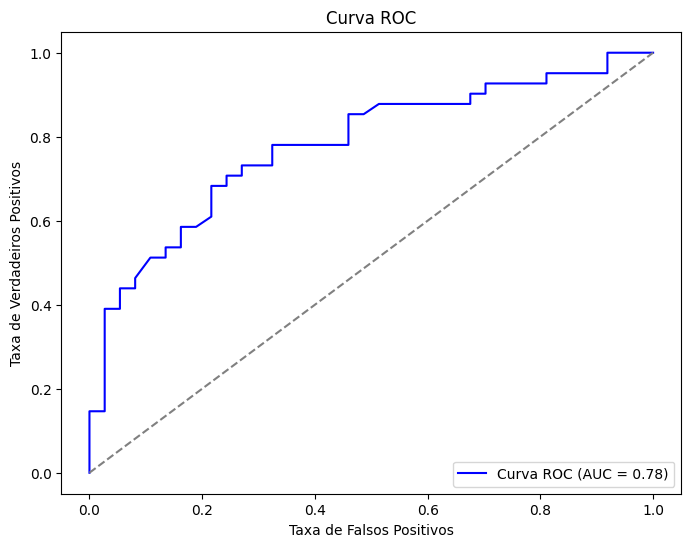

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.linear_model import LogisticRegression

# Supondo que 'data' seja o seu DataFrame com as variáveis explicativas 'idade', 'sexo', 'ecg' e a variável resposta 'dac'
X = data[['idade', 'sexo', 'ecg']]
y = data['dac']

# Ajustar o modelo de regressão logística e armazená-lo em lr3
lr3 = LogisticRegression()
lr3.fit(X, y)

# Obter as probabilidades preditas para a classe positiva
y_pred_proba = lr3.predict_proba(X)[:, 1]

# Calcular as taxas de verdadeiros e falsos positivos para diferentes limiares
fpr, tpr, thresholds = roc_curve(y, y_pred_proba)

# Calcular a AUC (Área sob a Curva)
roc_auc = auc(fpr, tpr)

# Plotar a curva ROC
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', label=f'Curva ROC (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  # Linha de referência
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC')
plt.legend(loc='lower right')
plt.show()


<Axes: xlabel='Predito', ylabel='Real'>

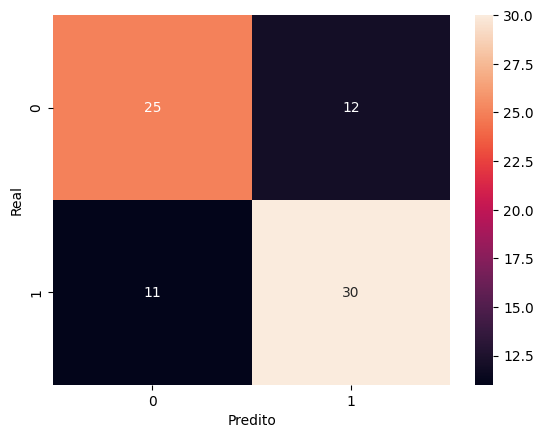

In [ ]:
import seaborn as sn

# Definir um ponto de corte específico, por exemplo, 0,5
cutoff = 0.5
y_pred_binario = (y_pred_proba >= cutoff).astype(int)

# Construir a matriz de confusão
confusion_matrix = pd.crosstab(y, y_pred_binario, rownames=['Real'], colnames=['Predito'])
sn.heatmap(confusion_matrix, annot=True)


Calculando as métricas:

In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

# Calcular a matriz de confusão
conf_matrix = confusion_matrix(y, y_pred_binario)

# Calcular as métricas
tn, fp, fn, tp = conf_matrix.ravel()  # tn: verdadeiro negativo, fp: falso positivo, fn: falso negativo, tp: verdadeiro positivo

sensibilidade = recall_score(y, y_pred_binario)  # Sensibilidade (Recall)
especificidade = tn / (tn + fp) if (tn + fp) > 0 else 0  # Especificidade
valor_preditivo_positivo = precision_score(y, y_pred_binario)  # Valor Preditivo Positivo
valor_preditivo_negativo = fn / (fn + tn) if (fn + tn) > 0 else 0  # Valor Preditivo Negativo
f1 = f1_score(y, y_pred_binario)  # F1 Score
acuracia = accuracy_score(y, y_pred_binario)  # Acurácia

# Exibir os resultados
print(f"Sensibilidade: {sensibilidade:.2f}")
print(f"Especificidade: {especificidade:.2f}")
print(f"Valor Preditivo Positivo: {valor_preditivo_positivo:.2f}")
print(f"Valor Preditivo Negativo: {valor_preditivo_negativo:.2f}")
print(f"F1 Score: {f1:.2f}")
print(f"Acurácia: {acuracia:.2f}")

Sensibilidade: 0.73
Especificidade: 0.68
Valor Preditivo Positivo: 0.71
Valor Preditivo Negativo: 0.31
F1 Score: 0.72
Acurácia: 0.71


Em R, a curva ROC e a tabela de confusão, podem ser obtidas com:
```
# Curva ROC: precisa instalar a biblioteca Epi
require(Epi)
ROC(form=dac ~ sexo + ecg + idade,plot="ROC", data=dados)


# Regra de classificação: precisa instalar a biblioteca caret
pred_c <- ifelse(dados$pred > 0.5,1,0)
library(caret)
confusionMatrix(table(pred_c,dados$dac),positive="1")
```